In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib widget

import os
from pathlib import Path
os.chdir(Path().cwd().parent.parent)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from geo6.io.io import load_data
from geo6.config import Config

config = Config()

In [57]:
data = load_data()

## Microresp PCA

In [13]:
from geo6.pca import prepare_pca_data, calc_pca, plot_pca, print_pca_loadings

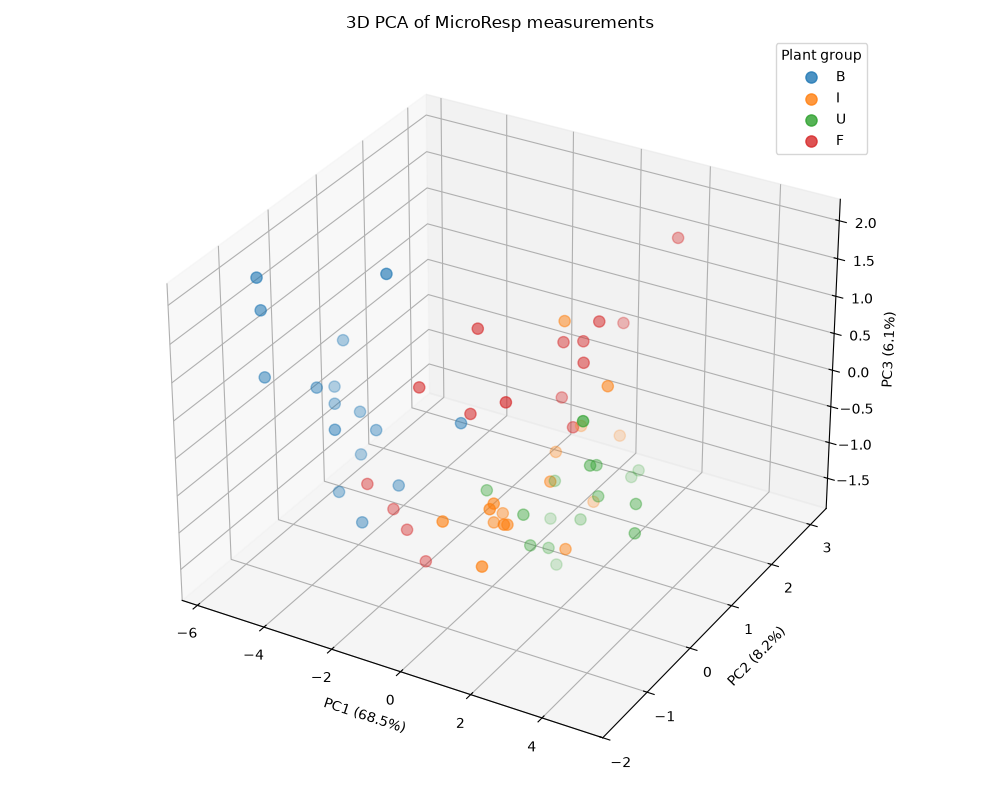

PC1    68.5%
PC2     8.2%
PC3     6.1%
dtype: str
Total variance explained by first 3 PCs: 82.9%

PCA loadings:
                        PC1       PC2       PC3
br_mg_per_g_h      0.276055 -0.191295  0.482551
sir_1_mg_per_g_h   0.323135  0.118003 -0.225308
sir_2_mg_per_g_h   0.326109 -0.064687 -0.173686
sir_3_mg_per_g_h   0.314837  0.105264 -0.270496
sir_4_mg_per_g_h   0.282041 -0.360659  0.170325
sir_5_mg_per_g_h   0.322379  0.025310 -0.193072
sir_6_mg_per_g_h   0.268764 -0.019246  0.490896
sir_7_mg_per_g_h   0.275527 -0.056066 -0.317741
sir_8_mg_per_g_h   0.307189 -0.249996  0.092748
sir_9_mg_per_g_h   0.142961  0.827175  0.199292
sir_10_mg_per_g_h  0.315394  0.053229 -0.262797
sir_11_mg_per_g_h  0.260782  0.224581  0.295702


In [14]:
microresp = data.microresp

# Select response vars
features = [
    'br_mg_per_g_h', 'sir_1_mg_per_g_h', 'sir_2_mg_per_g_h',
    'sir_3_mg_per_g_h', 'sir_4_mg_per_g_h', 'sir_5_mg_per_g_h', 
    'sir_6_mg_per_g_h', 'sir_7_mg_per_g_h', 'sir_8_mg_per_g_h',
    'sir_9_mg_per_g_h', 'sir_10_mg_per_g_h', 'sir_11_mg_per_g_h'
]

df_pca, X_scaled = prepare_pca_data(df=microresp, features=features)

pca, df_scores = calc_pca(X_scaled=X_scaled, df_pca=df_pca)

plot_pca(df=df_scores, pca=pca)

print_pca_loadings(pca=pca, features=features)

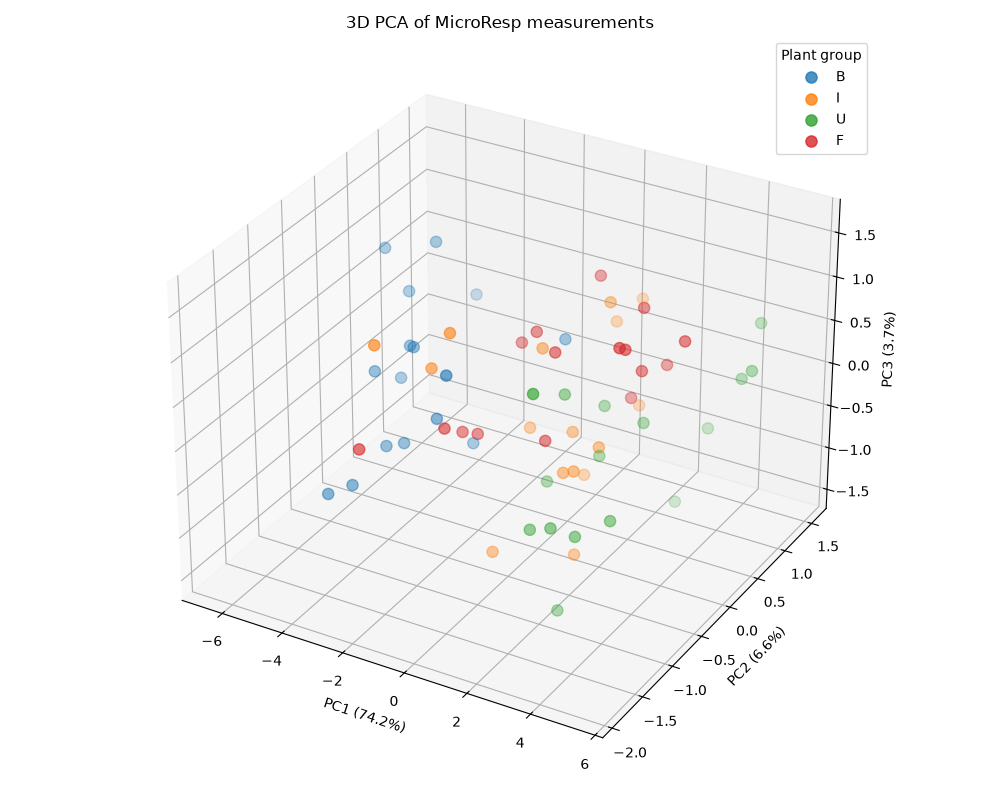

PC1    74.2%
PC2     6.6%
PC3     3.7%
dtype: str
Total variance explained by first 3 PCs: 84.5%


In [6]:
# Select the six MicroResp response variables
features = [
    'br_I1_mg_per_g_h',
    'br_U1_mg_per_g_h', 'br_F1_mg_per_g_h', 'sir_1_I1_mg_per_g_h',
    'sir_1_U1_mg_per_g_h', 'sir_1_F1_mg_per_g_h', 'br_I2_mg_per_g_h',
    'br_U2_mg_per_g_h', 'br_F2_mg_per_g_h', 'sir_1_I2_mg_per_g_h',
    'sir_1_U2_mg_per_g_h', 'sir_1_F2_mg_per_g_h'
]

df_pca, X_scaled = prepare_pca_data(df=microresp, features=features)

pca, df_scores = calc_pca(X_scaled=X_scaled, df_pca=df_pca)
 
plot_pca(df=df_scores, pca=pca)


In [9]:
print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print("\nCumulative explained variance:")
print(pca.explained_variance_ratio_.cumsum())

print("\nPCA loadings:")
print(pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=["PC1", "PC2", "PC3"],
))

Explained variance ratio:
[0.74202273 0.06585541 0.03724495]

Cumulative explained variance:
[0.74202273 0.80787814 0.84512309]

PCA loadings:
                          PC1       PC2       PC3
br_I1_mg_per_g_h     0.258926  0.489445 -0.229602
br_U1_mg_per_g_h     0.298701  0.202577  0.074639
br_F1_mg_per_g_h     0.290149  0.090016  0.360375
sir_1_I1_mg_per_g_h  0.287684  0.151361 -0.543287
sir_1_U1_mg_per_g_h  0.297423 -0.312024  0.033920
sir_1_F1_mg_per_g_h  0.303841 -0.179146 -0.237090
br_I2_mg_per_g_h     0.274855  0.338861 -0.073413
br_U2_mg_per_g_h     0.282306  0.146039  0.645854
br_F2_mg_per_g_h     0.276676  0.239005  0.060692
sir_1_I2_mg_per_g_h  0.299384 -0.319407 -0.081048
sir_1_U2_mg_per_g_h  0.296924 -0.362257  0.107923
sir_1_F2_mg_per_g_h  0.293973 -0.363884 -0.122072


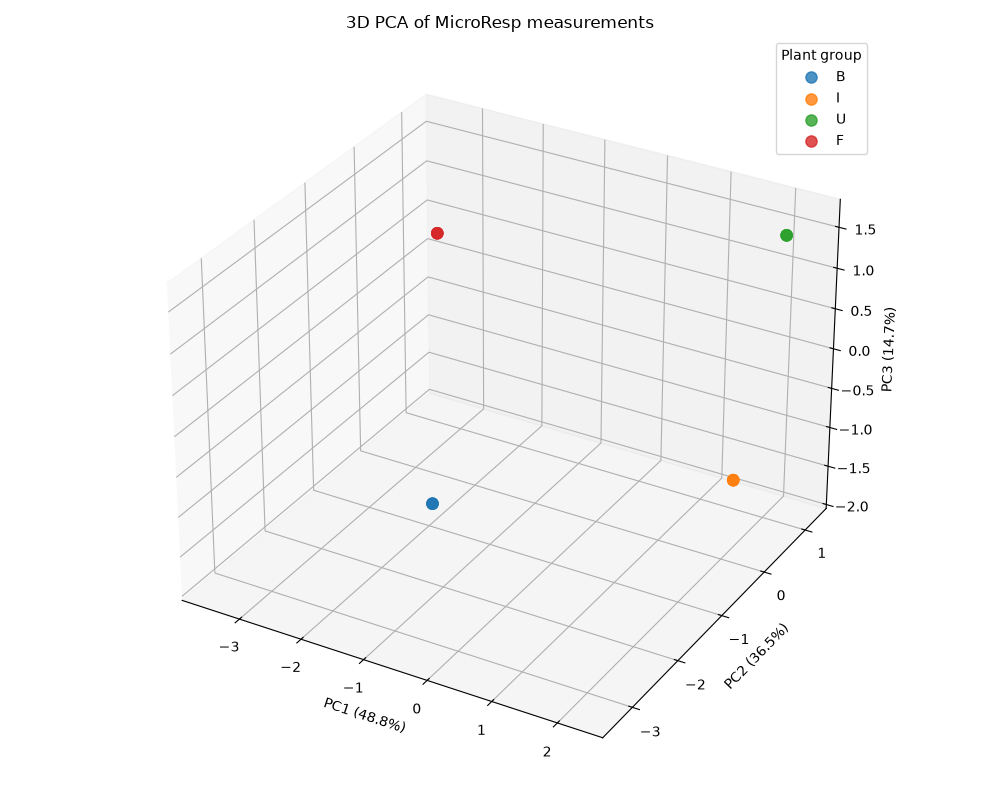

PC1    48.8%
PC2    36.5%
PC3    14.7%
dtype: str
Total variance explained by first 3 PCs: 100.0%

PCA loadings:
                           PC1       PC2       PC3
pnr_0_mg_per_kg_h_dm  0.393876  0.257577  0.029359
pnr_0_ste             0.276988  0.328640 -0.396537
pnr_W_mg_per_kg_h_dm  0.441690  0.114668 -0.022493
pnr_W_ste             0.345487  0.097708  0.510161
pnr_F_mg_per_kg_h_dm  0.428615  0.168102 -0.026680
pnr_F_ste             0.328302 -0.313466 -0.280247
pnr_I_mg_per_kg_h_dm  0.176768 -0.476520  0.111742
pnr_I_ste             0.215451 -0.282536  0.572286
pnr_U_mg_per_kg_h_dm -0.010911  0.511720  0.171141
pnr_U_ste            -0.290532  0.328146  0.364128


In [ ]:
nitrification_rate = data.nitrification_rate

# Select response vars
features = [
    # 'nitrate_n_mg_kg_dm', 'ammonium_n_mg_kg_dm', 
    'pnr_0_mg_per_kg_h_dm', 'pnr_0_ste',
    'pnr_W_mg_per_kg_h_dm', 'pnr_W_ste', 
    'pnr_F_mg_per_kg_h_dm', 'pnr_F_ste', 
    'pnr_I_mg_per_kg_h_dm', 'pnr_I_ste',
    'pnr_U_mg_per_kg_h_dm', 'pnr_U_ste'
]

df_pca, X_scaled = prepare_pca_data(df=nitrification_rate, features=features)

pca, df_scores = calc_pca(X_scaled=X_scaled, df_pca=df_pca)

plot_pca(df=df_scores, pca=pca)

print_pca_loadings(pca=pca, features=features)

## All

In [36]:
data.cation_exchange_capacity.columns

Index(['sample', 'type', 'subrep', 'group', 'cec_pot_cmolc_kg',
       'cec_eff_cmolc_kg'],
      dtype='str')

In [58]:
from functools import reduce
from dataclasses import fields

field_names = [field.name for field in fields(data)]
dfs = [getattr(data, name) for name in field_names]

keys = ['sample', 'type', 'subrep', 'group']

df_merged = reduce(
    lambda left, right: pd.merge(
        left,
        right,
        on=keys,
        how="outer",
        validate="one_to_one",
    ),
    dfs,
)

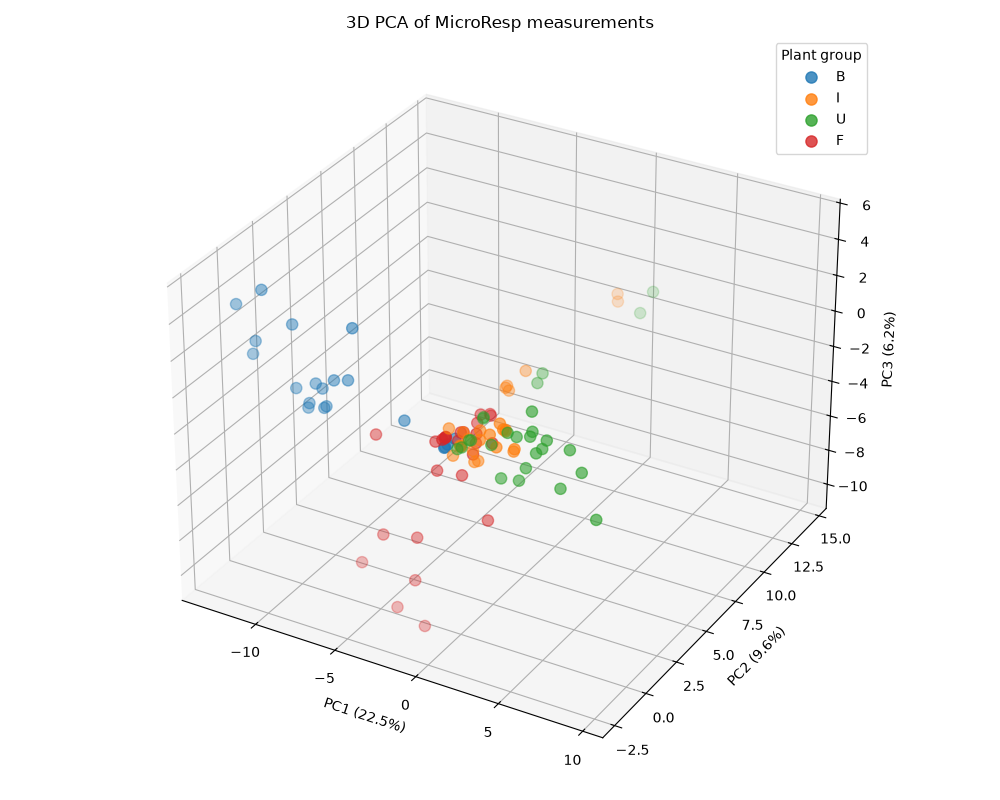

PC1    22.5%
PC2     9.6%
PC3     6.2%
dtype: str
Total variance explained by first 3 PCs: 38.2%

PCA loadings:
                          PC1       PC2       PC3
sand_percent         0.039541 -0.037702 -0.179874
silt_percent        -0.031822  0.033618  0.135680
clay_percent        -0.018065 -0.007619  0.080925
humus_percent        0.004826 -0.027039  0.150327
cec_pot_cmolc_kg    -0.009858  0.011962  0.212466
...                       ...       ...       ...
br_U2_mg_per_g_h     0.175978 -0.003436  0.062782
br_F2_mg_per_g_h     0.171298 -0.004739  0.042885
sir_1_I2_mg_per_g_h  0.194297  0.003526  0.049115
sir_1_U2_mg_per_g_h  0.190731 -0.007523  0.064505
sir_1_F2_mg_per_g_h  0.193049  0.002697  0.049276

[93 rows x 3 columns]


In [62]:
# Select response vars
features = df_merged.drop(columns=['sample', 'type', 'subrep', 'group']).columns.to_list()

df_pca, X_scaled = prepare_pca_data(df=df_merged, features=features)

pca, df_scores = calc_pca(X_scaled=X_scaled, df_pca=df_pca)

plot_pca(df=df_scores, pca=pca)

print_pca_loadings(pca=pca, features=features)

## Else

In [9]:
copper = data.copper
copper_sub = copper[["sample", "cu_ex_ug_kg_dm", "cu_org_ug_kg_dm", "cu_red_ug_kg_dm"]]


copper_agg = (
    copper_sub
    .groupby("sample")
    .agg(
        ["mean", "std"]
    )
    .reset_index()
)

C:\Users\Administrator\AppData\Local\Temp\ipykernel_6104\2136735052.py:1: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  data_cols = copper_agg.drop(columns="sample").columns.to_list()


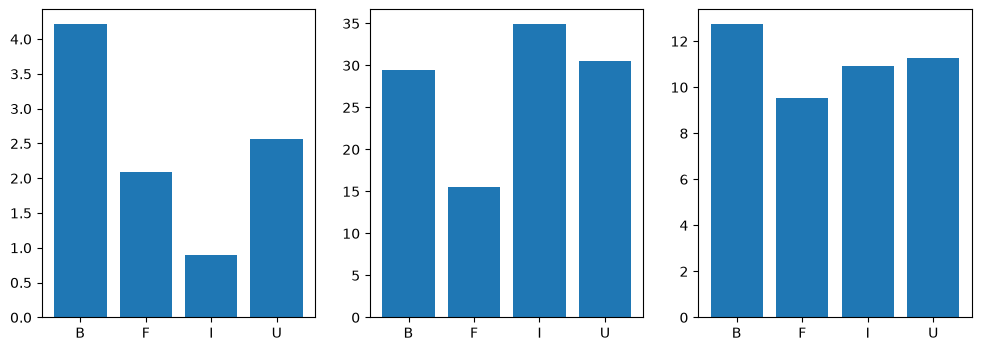

In [40]:
data_cols = copper_agg.drop(columns="sample").columns.to_list()

mean_cols = [col[0] for col in data_cols if col[1] == "mean"]
std_cols = [col[0] for col in data_cols if col[1] == "std"]


fig, axs = plt.subplots(figsize=(12, 4), ncols=3)

for i, col in enumerate(mean_cols):
    
    axs[i].bar(
        x=copper_agg["sample"],
        height=copper_agg[col]["mean"]
    )